# 08 · Financial evaluation and statistical analysis (task 8)

**Question:** holding the earnings surprise fixed, do releases with more positive text have higher
abnormal returns? This notebook runs, for every available text signal:

1. the **regression ladder** (SUE deciles, text, controls, sector FE; two-way clustered errors; Fama–MacBeth);
2. the **2×2 table** (beat / miss × positive / negative text) with clustered standard errors and CIs;
3. the **robustness grid** (sectors, size, periods, event windows, placebo, sample definitions);
4. automatic saving of every table and regression (`results/tables`, `results/regressions`).

Everything runs on the **validation split** until the holdout is frozen. The rate-shock analysis is in
`08b_rate_shock.ipynb` because it lives entirely in the holdout.

> **Outputs saved in this notebook come from the synthetic demo** (`SYNTHETIC = True`), because part 6
> has not produced LLM scores yet and part 5 has cleaned only 2006. The demo has a *known* answer:
> `llm__good_llm…` carries real text information, `llm__noise_llm…` is pure noise, and nothing predicts
> the placebo. Set `STEP78_SYNTHETIC=0` to run on the real data.

In [1]:
# --- Setup (same in every notebook) ----------------------------------------
import os, sys, warnings
from pathlib import Path

try:                                   # on Colab: mount Drive and move to this folder
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/S08 NLP/7_8_baselines_evaluation")
except ImportError:                    # on a laptop: run Jupyter from this folder
    pass

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "code"))

# SYNTHETIC = True runs everything on fake data with a planted effect and writes to
# results/_synthetic/ (never over the real results). Set STEP78_SYNTHETIC=1 or edit here.
SYNTHETIC = os.environ.get("STEP78_SYNTHETIC", "0") == "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

import settings as S
if SYNTHETIC:
    S.redirect_outputs("synthetic")
S.ensure_dirs()
import io_inputs as IO, outputs as OUT, pipeline as P
print("TEAM_DIR :", S.TEAM_DIR)
print("outputs  :", S.RESULTS)
print("mode     :", "SYNTHETIC DEMO" if SYNTHETIC else "real data")

TEAM_DIR : /Users/maximelacroix/Downloads/S08 NLP
outputs  : /Users/maximelacroix/Downloads/S08 NLP/7_8_baselines_evaluation/results/_synthetic
mode     : SYNTHETIC DEMO


In [2]:
ev, texts, sectors, scores, prov = P.load_all(SYNTHETIC)
panel = P.build_inputs(ev, texts, sectors)
if not S.SIGNALS.exists():                 # notebook 07 not run yet: build the baselines now
    P.save_signals(P.build_signals(panel, texts)[0])
sig = P.load_signals_aligned(panel, scores)
TEXTS = P.available_text_signals(sig)
EVAL = "validation"
d = panel[panel["split"] == EVAL].copy()
from panel import cs_rank
for t in TEXTS:                            # every signal as a within-season rank in [-0.5, 0.5]
    d[t + "_rk"] = cs_rank(sig.loc[d.index, t], d["season"])
print(f"{len(d):,} {EVAL} events, {d['season'].nunique()} seasons; text signals: {TEXTS or 'none yet'}")
TEXT = next((t for t in TEXTS if t.startswith("llm__")), TEXTS[0] if TEXTS else None)
print("signal shown in detail below:", TEXT)

model scores: 2 signals over 17,696 documents
panel: 17,696 events -> 13,514 in sample 'in_primary' without 2020
holdout guard: dropped 3,577 rows from 2021-2025
2,111 validation events, 12 seasons; text signals: ['lm_tone', 'lm_negshare', 'tfidf_ridge__car_0_1_ff4', 'tfidf_logit__up', 'llm__good_llm__tone_v1__raw', 'llm__noise_llm__tone_v1__raw']
signal shown in detail below: llm__good_llm__tone_v1__raw


## 1. The regression ladder

```
(1) y = SUE deciles + season FE
(2) y = text + season FE
(3) y = SUE deciles + text + season FE                     <- the main test
(4) (3) + log size, log #analysts, dispersion/price, prior 1m return + FF12 FE
(5) (4) + text x 1[miss]                                   <- does text matter more after a miss?
```

* Text enters as its within-season **rank**: the coefficient is the abnormal-return gap between the most
  and least positive release of a quarter, holding the rest fixed. Same units for every model.
* SUE enters as **decile dummies** (non-linear), so the text gets no credit for the S-curve.
* **Season FE** make the comparison purely within-quarter.
* **Standard errors: two-way clustered by firm and season.** Season clustering is the important one:
  releases of the same quarter share market news.
* Compare `(2)` with `(3)`: the drop in the text coefficient is how much of the "text effect" was really
  the surprise.

In [3]:
from regressions import incremental_info, regression_table
if TEXT:
    ii = incremental_info(d, TEXT + "_rk", S.PRIMARY_OUTCOME)
    keep = [TEXT + "_rk", "text_x_miss", "miss", "log_mktcap", "log_analysts", "disp_price", "ret_prior_1m_w"]
    display(regression_table(ii["fits"], keep))
else:
    print("no text signal yet")

  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']


,(1) SUE,(2) text,(3) SUE + text,(4) + controls,(5) + text x miss
llm__good_llm__tone_v1__raw_rk,,0.0589***,0.0380***,0.0377***,0.0429***
,,(18.43),(12.83),(14.26),(12.51)
text_x_miss,,,,,-0.0135
,,,,,(-1.64)
miss,,,,,-0.0143**
,,,,,(-2.13)
log_mktcap,,,,-0.0004,-0.0004
,,,,(-0.42),(-0.42)
log_analysts,,,,0.0035**,0.0034**
,,,,(2.44),(2.41)


**Fama–MacBeth** (one regression per season, then the average with Newey–West errors) is an
independent check that does not depend on the clustering formula, and `share_positive` shows whether
the effect is present in most seasons or driven by a few.

In [4]:
ii["fama_macbeth"] if TEXT else None

,variable,coef,se_nw,t_nw,share_positive,seasons
0,const,-0.0299,0.0053,-5.6939,0.0833,12
1,llm__good_llm__tone_v1__raw_rk,0.0385,0.0020,19.2643,1.0000,12
2,log_mktcap,-0.0003,0.0007,-0.4452,0.5833,12
3,log_analysts,0.0031,0.0014,2.2460,0.8333,12
4,disp_price,0.2990,0.5775,0.5178,0.4167,12
5,disp_missing,NaN,NaN,NaN,NaN,0
6,ret_prior_1m_w,-0.0074,0.0123,-0.6034,0.2500,12


## 2. The 2×2 table: surprise sign × text sign

Rows: beat (SUE > 0) / miss (SUE < 0); exact meets are excluded and counted. Columns: text above / below
its **within-season median**. Cells: mean reaction with a 95% CI clustered by season.

If the text only repeats the surprise, the two columns of each row are the same. The contrasts test
exactly that: the **text effect within beats**, **within misses**, their **average**, and the
difference-in-differences.

In [5]:
from two_by_two import two_by_two
if TEXT:
    tb = two_by_two(d.assign(**{TEXT: sig.loc[d.index, TEXT]}), TEXT, S.PRIMARY_OUTCOME)
    display(tb["matrix"]); display(tb["contrasts"].drop(columns=["signal", "outcome", "text_rule"]))
    print("excluded:", tb["excluded"])

,text negative,text positive
SUE > 0 (beat),"0.14% [-0.41, 0.68] n=268","2.02% [1.59, 2.44] n=602"
SUE < 0 (miss),"-3.45% [-3.91, -2.99] n=569","-1.84% [-2.57, -1.12] n=260"


,contrast,estimate,se_cluster,t_cluster,p_cluster,ci95_lo,ci95_hi
0,text effect | beat (beat_pos - beat_neg),0.0188,0.0027,6.9108,0.0000,0.0135,0.0241
1,text effect | miss (miss_pos - miss_neg),0.0160,0.0037,4.3881,0.0000,0.0089,0.0232
2,average text effect,0.0174,0.0030,5.8851,0.0000,0.0116,0.0232
3,diff-in-diff (beat effect - miss effect),0.0028,0.0025,1.0828,0.2789,-0.0022,0.0077
4,surprise effect | text pos (beat_pos - miss_pos),0.0386,0.0038,10.2334,0.0000,0.0312,0.0460
5,surprise effect | text neg (beat_neg - miss_neg),0.0358,0.0030,11.8557,0.0000,0.0299,0.0418
6,"beat, bad text vs miss, good text",0.0198,0.0053,3.7209,0.0002,0.0094,0.0302


excluded: {'meets (surprise == 0)': 408, 'missing outcome / signal / surprise': 0}


In [6]:
# The cell table with naive vs clustered standard errors: the ratio shows how much
# cross-sectional correlation within seasons inflates naive t-statistics.
if TEXT:
    c = tb["cells"][["cell", "n", "mean", "se_naive", "se_cluster", "ci95_lo", "ci95_hi"]].copy()
    c["se_ratio"] = c["se_cluster"] / c["se_naive"]
    display(c)

,cell,n,mean,se_naive,se_cluster,ci95_lo,ci95_hi,se_ratio
0,beat_textpos,602,0.0202,0.0021,0.0022,0.0159,0.0244,1.0402
1,beat_textneg,268,0.0014,0.0031,0.0028,-0.0041,0.0068,0.8920
2,miss_textpos,260,-0.0184,0.0031,0.0037,-0.0257,-0.0112,1.1749
3,miss_textneg,569,-0.0345,0.0021,0.0023,-0.0391,-0.0299,1.1038


## 3. Robustness

The same two statistics (text coefficient of spec (3), rank IC) re-estimated on subsets and variants.
The **placebo** row (`ar_m1`, the day before the release) must be close to zero: a text signal that
"predicts" a return realised *before* the release reveals a timing error or a leak, not information.

In [7]:
from robustness import robustness_grid
if TEXT:
    rob = robustness_grid(d, TEXT + "_rk", S.PRIMARY_OUTCOME)
    display(rob[["dimension", "group", "outcome", "n", "seasons", "coef_text", "t_text", "mean_ic", "ic_t_nw"]])

,dimension,group,outcome,n,seasons,coef_text,t_text,mean_ic,ic_t_nw
0,baseline,all,car_0_1_ff4,2111,12,0.0380,12.8287,0.3141,25.1900
1,sector (FF12),BusEq,car_0_1_ff4,182,12,NaN,NaN,NaN,NaN
2,sector (FF12),Chems,car_0_1_ff4,194,12,NaN,NaN,NaN,NaN
3,sector (FF12),Durbl,car_0_1_ff4,208,12,NaN,NaN,NaN,NaN
4,sector (FF12),Enrgy,car_0_1_ff4,199,12,NaN,NaN,NaN,NaN
5,sector (FF12),Hlth,car_0_1_ff4,189,12,NaN,NaN,NaN,NaN
6,sector (FF12),Manuf,car_0_1_ff4,158,12,NaN,NaN,NaN,NaN
7,sector (FF12),Money,car_0_1_ff4,189,12,NaN,NaN,NaN,NaN
8,sector (FF12),NoDur,car_0_1_ff4,198,12,NaN,NaN,NaN,NaN
9,sector (FF12),Shops,car_0_1_ff4,191,12,NaN,NaN,NaN,NaN


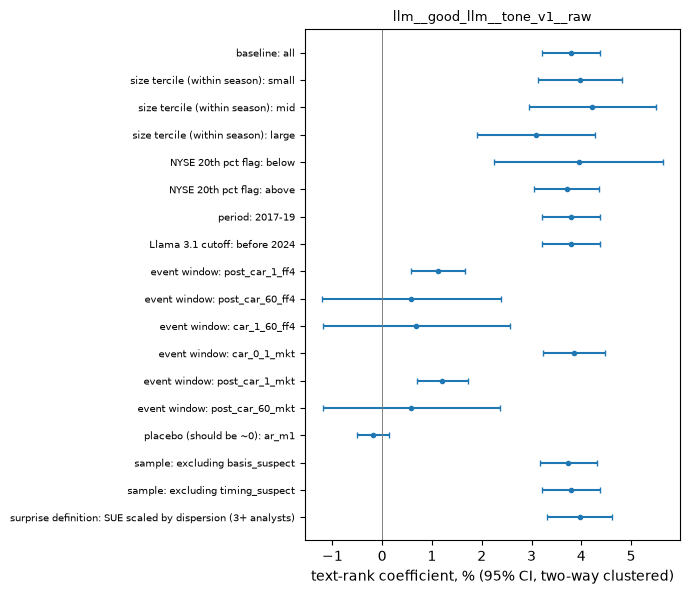

In [8]:
if TEXT:
    r = rob.dropna(subset=["coef_text"]).copy()
    r["se"] = r["coef_text"] / r["t_text"]
    r["label"] = r["dimension"] + ": " + r["group"]
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(r) + 1))
    ax.errorbar(r["coef_text"] * 100, range(len(r)), xerr=1.96 * r["se"] * 100, fmt="o", ms=3, capsize=2)
    ax.axvline(0, color="grey", lw=.7); ax.set_yticks(range(len(r))); ax.set_yticklabels(r["label"], fontsize=7)
    ax.invert_yaxis(); ax.set_xlabel("text-rank coefficient, % (95% CI, two-way clustered)")
    ax.set_title(TEXT, fontsize=9); plt.tight_layout(); OUT.save_figure(fig, "t8_robustness_" + TEXT); plt.show()

## 4. Every signal, every outcome: run and save everything

`pipeline.evaluate` repeats sections 1–3 for every text signal and every outcome and saves:

| File | Content |
|---|---|
| `t7_compare__<outcome>__validation` | task 7 comparison table |
| `t8_incremental_summary__validation` | text coefficient across specs (1)–(5) and Fama–MacBeth, every signal × outcome |
| `t8_regressions__<signal>__car_0_1_ff4__validation` | journal-style regression table |
| `t8_2x2_matrix__…`, `t8_2x2_cells__…`, `t8_2x2_contrasts__…` | the 2×2 table |
| `t8_robustness__validation` | the robustness grid |
| `results/regressions/*.txt` | full statsmodels output of every fit |

Each file is logged in `logs/runs.jsonl` with its sha256 and the upstream versions.

In [9]:
res = P.evaluate(panel, sig, EVAL, prov=prov)
summ = res.get("t8_incremental_summary", pd.DataFrame())
if len(summ):
    view = summ[summ["spec"].isin(["(3) SUE + text", "(FM) SUE + text + controls, Fama-MacBeth"])]
    display(view.pivot_table(index="text_signal", columns=["spec", "outcome"], values="t_text").round(2))

text signals evaluated: ['lm_tone', 'lm_negshare', 'tfidf_ridge__car_0_1_ff4', 'tfidf_logit__up', 'llm__good_llm__tone_v1__raw', 'llm__noise_llm__tone_v1__raw']


compare [car_0_1_ff4, validation]: 2,111 events on common support, 12 seasons


compare [post_car_1_ff4, validation]: 2,111 events on common support, 12 seasons


compare [post_car_60_ff4, validation]: 2,111 events on common support, 12 seasons


compare [car_1_60_ff4, validation]: 2,111 events on common support, 12 seasons
  ols: dropped constant regressors ['disp_missing']


  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']


... (8 outputs left out)

  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']


  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']


  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']
  ols: dropped constant regressors ['disp_missing']


spec                            (3) SUE + text                                                         (FM) SUE + text + controls, Fama-MacBeth                                          \
outcome                                  ar_m1 car_0_1_ff4 car_1_60_ff4 post_car_1_ff4 post_car_60_ff4                                    ar_m1 car_0_1_ff4 car_1_60_ff4 post_car_1_ff4   
text_signal                                                                                                                                                                               
llm__good_llm__tone_v1__raw_rk         -1.1300     12.8300       0.7200         3.9800          0.6400                                  -1.3000     19.2600       0.8800         5.5200   
llm__noise_llm__tone_v1__raw_rk         0.7400      0.7100      -0.3700         2.4000         -0.3500                                   1.1200      0.6400      -0.3000         3.9300   
lm_negshare_rk                         -0.2900      7.4600       0.2500         3.9200          2.2700                                  -0.2600      9.2200       0.4700         5.4300   
lm_tone_rk                             -0.6800      7.4300       1.3700         5.2800          2.0800                                  -1.2800      8.4200       1.5200         7.6500   
tfidf_logit__up_rk                      0.5800      4.8600       1.7000         3.4900          0.9300                                   0.5600      4.4600       1.6000         4.9100   
tfidf_ridge__car_0_1_ff4_rk            -0.1100      5.1600       1.7600         3.4500          1.2100                                  -0.5200      4.9400       1.7400         3.7300   

spec                                             
outcome                         post_car_60_ff4  
text_signal                                      
llm__good_llm__tone_v1__raw_rk           0.3100  
llm__noise_llm__tone_v1__raw_rk         -1.0500  
lm_negshare_rk                           2.8900  
lm_tone_rk                               2.9200  
tfidf_logit__up_rk                       1.9000  
tfidf_ridge__car_0_1_ff4_rk              1.9500

## 5. Reading the results: a checklist

1. **Main test:** is the text coefficient in spec (3) significant with two-way clustering *and* in
   Fama–MacBeth, for the reaction window?
2. **Beyond the surprise:** how much does the coefficient fall from (2) to (3)? A large fall means the
   model mostly re-reads the EPS number.
3. **2×2:** is the text effect present within beats *and* within misses?
4. **Placebo:** is the `ar_m1` coefficient (controlling for SUE) close to zero?
5. **Priced in?** A text effect in `car_0_1_ff4` but not in `post_car_60_ff4` / `car_1_60_ff4` means the
   market prices the text at release.
6. **Robustness:** same sign across sectors, size terciles and periods? Effects concentrated in small
   firms are a different (and weaker) result.
7. **Validation has 12 seasons:** |t| < 3 is weak. The holdout decides.